# Tennessee Eastman Dataset Exploration

This notebook is a simple, commented walkthrough for comparing the healthy and faulty Tennessee Eastman training data.

We will:
- load the datasets,
- inspect their shapes and columns,
- compare healthy vs. faulty rows side by side, and
- visualize one example fault (Fault 6) for a single sensor so the difference is easy to see.


In [ ]:
# Cell 2: Import Required Libraries

# pandas is used to load and inspect tabular data.
import pandas as pd

# numpy helps with numeric operations and array handling.
import numpy as np

# matplotlib is used for plotting.
import matplotlib.pyplot as plt

# seaborn makes plots look cleaner and easier to read.
import seaborn as sns

# Path is used to locate files reliably in the project folder.
from pathlib import Path

# Optional: use a default style for cleaner charts.
sns.set_style('whitegrid')


## Load Healthy and Faulty Datasets

The dataset files are `.RData` files, so we use `pyreadr` to read them into pandas DataFrames.

This step is important because it lets us inspect the raw structure before doing any analysis.


In [ ]:
# Cell 3: Load Healthy and Faulty Datasets

# pyreadr is needed to read the .RData files.
import pyreadr

# Project root path
project_root = Path.cwd()

# File paths
fault_free_path = project_root / '../data/TEP_FaultFree_Training.RData'
faulty_path = project_root / '../data/TEP_Faulty_Training.RData'

# Read the datasets
# The result from pyreadr is a dictionary-like object, so we select the DataFrame inside it.
result_fault_free = pyreadr.read_r(fault_free_path)
fault_free = result_fault_free['fault_free_training']

result_faulty = pyreadr.read_r(faulty_path)
faulty = result_faulty['faulty_training']

# Print a quick confirmation so we can see which files were loaded.
print(f'Loaded fault-free data from: {fault_free_path.name}')
print(f'Loaded faulty data from: {faulty_path.name}')

# Show the type and a small preview of each dataset.
print('\nFault-free data type:', type(fault_free).__name__)
print('Fault-free shape:', fault_free.shape)

print('\nFaulty data type:', type(faulty).__name__)
print('Faulty shape:', faulty.shape)


Loaded fault-free data from: TEP_FaultFree_Training.RData
Loaded faulty data from: TEP_Faulty_Training.RData

Fault-free data type: DataFrame
Fault-free shape: (250000, 55)

Faulty data type: DataFrame
Faulty shape: (5000000, 55)


## Inspect Columns, Shapes, and Basic Statistics

Now that the data is loaded, we can inspect the structure.

This helps us understand:
- how many rows/columns each dataset has,
- what the first few records look like, and
- whether the columns are what we expect.


In [ ]:
# Cell 4: Inspect Columns, Shapes, and Basic Statistics

# Display the column names for both datasets.
print('Fault-free columns:')
print(fault_free.columns.tolist())
print('\nFaulty columns:')
print(faulty.columns.tolist())

# Display the first few rows of each dataset.
print('\nFirst 5 rows of fault-free data:')
display(fault_free.head())

print('\nFirst 5 rows of faulty data:')
display(faulty.head())

# Quick summary statistics for numeric columns.
print('\nFault-free summary:')
display(fault_free.describe().round(4))

print('\nFaulty summary:')
display(faulty.describe().round(4))


Fault-free columns:
['faultNumber', 'simulationRun', 'sample', 'xmeas_1', 'xmeas_2', 'xmeas_3', 'xmeas_4', 'xmeas_5', 'xmeas_6', 'xmeas_7', 'xmeas_8', 'xmeas_9', 'xmeas_10', 'xmeas_11', 'xmeas_12', 'xmeas_13', 'xmeas_14', 'xmeas_15', 'xmeas_16', 'xmeas_17', 'xmeas_18', 'xmeas_19', 'xmeas_20', 'xmeas_21', 'xmeas_22', 'xmeas_23', 'xmeas_24', 'xmeas_25', 'xmeas_26', 'xmeas_27', 'xmeas_28', 'xmeas_29', 'xmeas_30', 'xmeas_31', 'xmeas_32', 'xmeas_33', 'xmeas_34', 'xmeas_35', 'xmeas_36', 'xmeas_37', 'xmeas_38', 'xmeas_39', 'xmeas_40', 'xmeas_41', 'xmv_1', 'xmv_2', 'xmv_3', 'xmv_4', 'xmv_5', 'xmv_6', 'xmv_7', 'xmv_8', 'xmv_9', 'xmv_10', 'xmv_11']

Faulty columns:
['faultNumber', 'simulationRun', 'sample', 'xmeas_1', 'xmeas_2', 'xmeas_3', 'xmeas_4', 'xmeas_5', 'xmeas_6', 'xmeas_7', 'xmeas_8', 'xmeas_9', 'xmeas_10', 'xmeas_11', 'xmeas_12', 'xmeas_13', 'xmeas_14', 'xmeas_15', 'xmeas_16', 'xmeas_17', 'xmeas_18', 'xmeas_19', 'xmeas_20', 'xmeas_21', 'xmeas_22', 'xmeas_23', 'xmeas_24', 'xmeas_25', 'x

,faultNumber,simulationRun,sample,xmeas_1,xmeas_2,xmeas_3,xmeas_4,xmeas_5,xmeas_6,xmeas_7,...,xmv_2,xmv_3,xmv_4,xmv_5,xmv_6,xmv_7,xmv_8,xmv_9,xmv_10,xmv_11
0,0.0,1.0,1,0.25038,3674.0,4529.0,9.2320,26.889,42.402,2704.3,...,53.744,24.657,62.544,22.137,39.935,42.323,47.757,47.510,41.258,18.447
1,0.0,1.0,2,0.25109,3659.4,4556.6,9.4264,26.721,42.576,2705.0,...,53.414,24.588,59.259,22.084,40.176,38.554,43.692,47.427,41.359,17.194
2,0.0,1.0,3,0.25038,3660.3,4477.8,9.4426,26.875,42.070,2706.2,...,54.357,24.666,61.275,22.380,40.244,38.990,46.699,47.468,41.199,20.530
3,0.0,1.0,4,0.24977,3661.3,4512.1,9.4776,26.758,42.063,2707.2,...,53.946,24.725,59.856,22.277,40.257,38.072,47.541,47.658,41.643,18.089
4,0.0,1.0,5,0.29405,3679.0,4497.0,9.3381,26.889,42.650,2705.1,...,53.658,28.797,60.717,21.947,39.144,41.955,47.645,47.346,41.507,18.461



First 5 rows of faulty data:


,faultNumber,simulationRun,sample,xmeas_1,xmeas_2,xmeas_3,xmeas_4,xmeas_5,xmeas_6,xmeas_7,...,xmv_2,xmv_3,xmv_4,xmv_5,xmv_6,xmv_7,xmv_8,xmv_9,xmv_10,xmv_11
0,1,1.0,1,0.25038,3674.0,4529.0,9.2320,26.889,42.402,2704.3,...,53.744,24.657,62.544,22.137,39.935,42.323,47.757,47.510,41.258,18.447
1,1,1.0,2,0.25109,3659.4,4556.6,9.4264,26.721,42.576,2705.0,...,53.414,24.588,59.259,22.084,40.176,38.554,43.692,47.427,41.359,17.194
2,1,1.0,3,0.25038,3660.3,4477.8,9.4426,26.875,42.070,2706.2,...,54.357,24.666,61.275,22.380,40.244,38.990,46.699,47.468,41.199,20.530
3,1,1.0,4,0.24977,3661.3,4512.1,9.4776,26.758,42.063,2707.2,...,53.946,24.725,59.856,22.277,40.257,38.072,47.541,47.658,41.643,18.089
4,1,1.0,5,0.29405,3679.0,4497.0,9.3381,26.889,42.650,2705.1,...,53.658,28.797,60.717,21.947,39.144,41.955,47.645,47.346,41.507,18.461



Fault-free summary:


,faultNumber,simulationRun,sample,xmeas_1,xmeas_2,xmeas_3,xmeas_4,xmeas_5,xmeas_6,xmeas_7,...,xmv_2,xmv_3,xmv_4,xmv_5,xmv_6,xmv_7,xmv_8,xmv_9,xmv_10,xmv_11
count,250000.0,250000.0000,250000.0000,250000.0000,250000.0000,250000.0000,250000.0000,250000.0000,250000.0000,250000.0000,...,250000.0000,250000.0000,250000.0000,250000.0000,250000.0000,250000.0000,250000.0000,250000.0000,250000.0000,250000.0000
mean,0.0,250.5000,250.5000,0.2505,3663.7857,4508.8198,9.3471,26.9022,42.3376,2705.0379,...,53.9737,24.6395,61.2985,22.2166,40.0555,38.0989,46.5343,47.9586,41.1043,18.1187
std,0.0,144.3376,144.3376,0.0309,34.0064,39.2154,0.0857,0.2115,0.2185,7.5256,...,0.4697,3.0377,1.2438,0.5302,1.5268,2.9653,2.3513,2.7165,0.5408,1.4637
min,0.0,1.0000,1.0000,0.1224,3511.8000,4336.9000,8.9727,25.9510,41.3940,2672.3000,...,52.0950,11.9770,55.9610,19.7490,33.3890,25.9590,36.9370,36.6410,38.5860,11.7050
25%,0.0,125.7500,125.7500,0.2298,3640.8000,4482.4000,9.2893,26.7580,42.1880,2700.1000,...,53.6570,22.6020,60.4530,21.8640,39.0210,36.0810,44.9310,46.2650,40.7400,17.1300
50%,0.0,250.5000,250.5000,0.2505,3663.7000,4508.8000,9.3471,26.9020,42.3380,2705.0000,...,53.9740,24.6440,61.2980,22.2170,40.0580,38.0910,46.5300,47.8200,41.1040,18.1190
75%,0.0,375.2500,375.2500,0.2712,3686.8000,4535.3000,9.4051,27.0460,42.4870,2710.0000,...,54.2900,26.6740,62.1440,22.5680,41.0840,40.1170,48.1400,49.6510,41.4700,19.1110
max,0.0,500.0000,500.0000,0.3917,3808.4000,4683.7000,9.7298,27.8180,43.2570,2739.1000,...,56.1180,38.3510,66.4430,24.5250,47.4980,50.7290,56.4430,59.6160,43.9300,24.7620



Faulty summary:


,faultNumber,simulationRun,sample,xmeas_1,xmeas_2,xmeas_3,xmeas_4,xmeas_5,xmeas_6,xmeas_7,...,xmv_2,xmv_3,xmv_4,xmv_5,xmv_6,xmv_7,xmv_8,xmv_9,xmv_10,xmv_11
count,5.000000e+06,5.000000e+06,5.000000e+06,5.000000e+06,5.000000e+06,5.000000e+06,5.000000e+06,5.000000e+06,5.000000e+06,5.000000e+06,...,5.000000e+06,5.000000e+06,5.000000e+06,5.000000e+06,5.000000e+06,5.000000e+06,5.000000e+06,5.000000e+06,5.000000e+06,5.000000e+06
mean,1.050000e+01,2.505000e+02,2.505000e+02,2.614000e-01,3.663777e+03,4.506046e+03,9.370300e+00,2.690160e+01,4.236420e+01,2.723005e+03,...,5.431750e+01,3.043180e+01,6.324830e+01,2.295490e+01,3.992300e+01,3.807270e+01,4.643740e+01,5.060600e+01,4.194850e+01,1.884380e+01
std,5.766300e+00,1.443373e+02,1.443373e+02,1.495000e-01,4.316940e+01,1.110368e+02,3.646000e-01,2.320000e-01,3.172000e-01,7.599380e+01,...,5.258100e+00,2.048360e+01,7.400100e+00,1.108260e+01,1.293350e+01,2.949100e+00,2.358500e+00,1.759840e+01,1.001230e+01,5.176700e+00
min,1.000000e+00,1.000000e+00,1.000000e+00,-4.700000e-03,3.327400e+03,3.540700e+03,6.639900e+00,2.538600e+01,3.965600e+01,2.413800e+03,...,3.118400e+01,-2.719000e-01,-4.900000e-03,-9.940000e-02,0.000000e+00,2.280100e+01,3.492300e+01,-3.636000e-01,-2.810000e-01,-5.300000e-03
25%,5.750000e+00,1.257500e+02,1.257500e+02,2.183000e-01,3.636500e+03,4.469000e+03,9.264200e+00,2.676000e+01,4.218100e+01,2.697600e+03,...,5.349700e+01,2.228000e+01,6.031400e+01,2.142300e+01,3.831300e+01,3.604900e+01,4.487800e+01,4.547900e+01,4.057500e+01,1.714300e+01
50%,1.050000e+01,2.505000e+02,2.505000e+02,2.511000e-01,3.663300e+03,4.508500e+03,9.355200e+00,2.690100e+01,4.234800e+01,2.705600e+03,...,5.397000e+01,2.521500e+01,6.149900e+01,2.212900e+01,3.996700e+01,3.815000e+01,4.633900e+01,4.806500e+01,4.120600e+01,1.829500e+01
75%,1.525000e+01,3.752500e+02,3.752500e+02,2.832000e-01,3.690200e+03,4.548000e+03,9.456800e+00,2.704300e+01,4.252400e+01,2.715000e+03,...,5.444300e+01,2.879700e+01,6.284100e+01,2.273800e+01,4.150700e+01,3.999100e+01,4.803100e+01,5.188700e+01,4.194900e+01,1.953700e+01
max,2.000000e+01,5.000000e+02,5.000000e+02,1.017500e+00,3.906700e+03,5.175800e+03,1.224000e+01,2.848600e+01,4.465300e+01,3.000500e+03,...,1.000000e+02,1.001900e+02,1.000200e+02,1.001100e+02,9.752800e+01,5.312100e+01,5.998000e+01,1.005200e+02,1.003200e+02,1.000100e+02


## Prepare a Side-by-Side Healthy vs Faulty Comparison

A useful way to compare the datasets is to line them up on a shared index.

In this notebook, we will:
- align the healthy and faulty rows by sample position,
- rename the columns so it is clear which side is healthy vs. faulty, and
- inspect a few rows side by side.


In [ ]:
# Cell 5: Prepare a Side-by-Side Healthy vs Faulty Comparison

# For a clean comparison, we will use the first simulation run from each dataset.
healthy_run = fault_free[fault_free['simulationRun'] == 1].copy()
faulty_run = faulty[faulty['simulationRun'] == 1].copy()

# Keep the same sample ordering so we can compare rows by position.
healthy_run = healthy_run.sort_values('sample').reset_index(drop=True)
faulty_run = faulty_run.sort_values('sample').reset_index(drop=True)

# Rename columns so it is easy to see which side is healthy vs faulty.
healthy_cols = {col: f'healthy_{col}' for col in healthy_run.columns}
faulty_cols = {col: f'faulty_{col}' for col in faulty_run.columns}

healthy_run = healthy_run.rename(columns=healthy_cols)
faulty_run = faulty_run.rename(columns=faulty_cols)

# Keep only the shared row index for a simple side-by-side view.
# We assume the first 1000 rows are enough for a quick visual inspection.
comparison = pd.concat([healthy_run.head(1000).reset_index(drop=True),
                       faulty_run.head(1000).reset_index(drop=True)],
                      axis=1)

# Print a few comparison rows.
print('Side-by-side comparison (first 10 rows):')
display(comparison.head(10))


Side-by-side comparison (first 10 rows):


,healthy_faultNumber,healthy_simulationRun,healthy_sample,healthy_xmeas_1,healthy_xmeas_2,healthy_xmeas_3,healthy_xmeas_4,healthy_xmeas_5,healthy_xmeas_6,healthy_xmeas_7,...,faulty_xmv_2,faulty_xmv_3,faulty_xmv_4,faulty_xmv_5,faulty_xmv_6,faulty_xmv_7,faulty_xmv_8,faulty_xmv_9,faulty_xmv_10,faulty_xmv_11
0,0.0,1.0,1.0,0.25038,3674.0,4529.0,9.2320,26.889,42.402,2704.3,...,53.744,24.657,62.544,22.137,39.935,42.323,47.757,47.51,41.258,18.447
1,0.0,1.0,2.0,0.25109,3659.4,4556.6,9.4264,26.721,42.576,2705.0,...,53.744,24.657,62.544,22.137,39.935,42.323,47.757,47.51,41.258,18.447
2,0.0,1.0,3.0,0.25038,3660.3,4477.8,9.4426,26.875,42.070,2706.2,...,53.744,24.657,62.544,22.137,39.935,42.323,47.757,47.51,41.258,18.447
3,0.0,1.0,4.0,0.24977,3661.3,4512.1,9.4776,26.758,42.063,2707.2,...,53.744,24.657,62.544,22.137,39.935,42.323,47.757,47.51,41.258,18.447
4,0.0,1.0,5.0,0.29405,3679.0,4497.0,9.3381,26.889,42.650,2705.1,...,53.744,24.657,62.544,22.137,39.935,42.323,47.757,47.51,41.258,18.447
5,0.0,1.0,6.0,0.29303,3691.7,4502.2,9.3780,27.111,41.999,2703.8,...,53.744,24.657,62.544,22.137,39.935,42.323,47.757,47.51,41.258,18.447
6,0.0,1.0,7.0,0.24301,3658.8,4541.6,9.3374,26.623,42.448,2704.0,...,53.744,24.657,62.544,22.137,39.935,42.323,47.757,47.51,41.258,18.447
7,0.0,1.0,8.0,0.24090,3653.3,4500.0,9.3495,27.075,42.412,2704.9,...,53.744,24.657,62.544,22.137,39.935,42.323,47.757,47.51,41.258,18.447
8,0.0,1.0,9.0,0.29416,3654.3,4454.7,9.3213,27.363,42.238,2703.2,...,53.744,24.657,62.544,22.137,39.935,42.323,47.757,47.51,41.258,18.447
9,0.0,1.0,10.0,0.29372,3675.9,4487.4,9.4107,26.809,42.144,2705.3,...,53.744,24.657,62.544,22.137,39.935,42.323,47.757,47.51,41.258,18.447


## Select and Highlight Fault 6 Example

For this example, we will look at **Fault 6** and compare one sensor across healthy and faulty runs.

The key idea is to keep the same sensor and same simulation run, then see how the values change once the fault begins.


In [ ]:
# Cell 6: Select and Highlight Fault 6 Example

# We choose one example fault and one example sensor.
fault_number = 6
sensor = 'xmeas_16'
run_id = 1
fault_start = 20

# Select the first simulation run for the healthy dataset.
healthy_selected = fault_free[
    (fault_free['simulationRun'] == run_id)
].sort_values('sample').copy()

# Select the first simulation run for Fault 6.
faulty_selected = faulty[
    (faulty['faultNumber'] == fault_number) &
    (faulty['simulationRun'] == run_id)
].sort_values('sample').copy()

# Check that the chosen sensor exists in both datasets.
assert sensor in healthy_selected.columns, f'{sensor} missing from healthy data'
assert sensor in faulty_selected.columns, f'{sensor} missing from faulty data'

# Compute a simple difference between the two series after the fault begins.
healthy_after = healthy_selected[healthy_selected['sample'] > fault_start]
faulty_after = faulty_selected[faulty_selected['sample'] > fault_start]

healthy_mean = healthy_selected[sensor].mean()
faulty_mean = faulty_selected[sensor].mean()

print(f'Healthy mean for {sensor} (run {run_id}): {healthy_mean:.4f}')
print(f'Fault {fault_number} mean for {sensor} (run {run_id}): {faulty_mean:.4f}')
print(f'Difference after sample {fault_start}: {faulty_after[sensor].mean() - healthy_after[sensor].mean():.4f}')


Healthy mean for xmeas_16 (run 1): 3101.7494
Fault 6 mean for xmeas_16 (run 1): 3385.6184
Difference after sample 20: 295.6969


## Visualize the Same Sensor in Healthy vs Faulty Data

This final section creates a chart so you can see the healthy and faulty traces together.

The vertical line marks the point where the fault is expected to begin (around sample 20), making the difference easier to recognize.


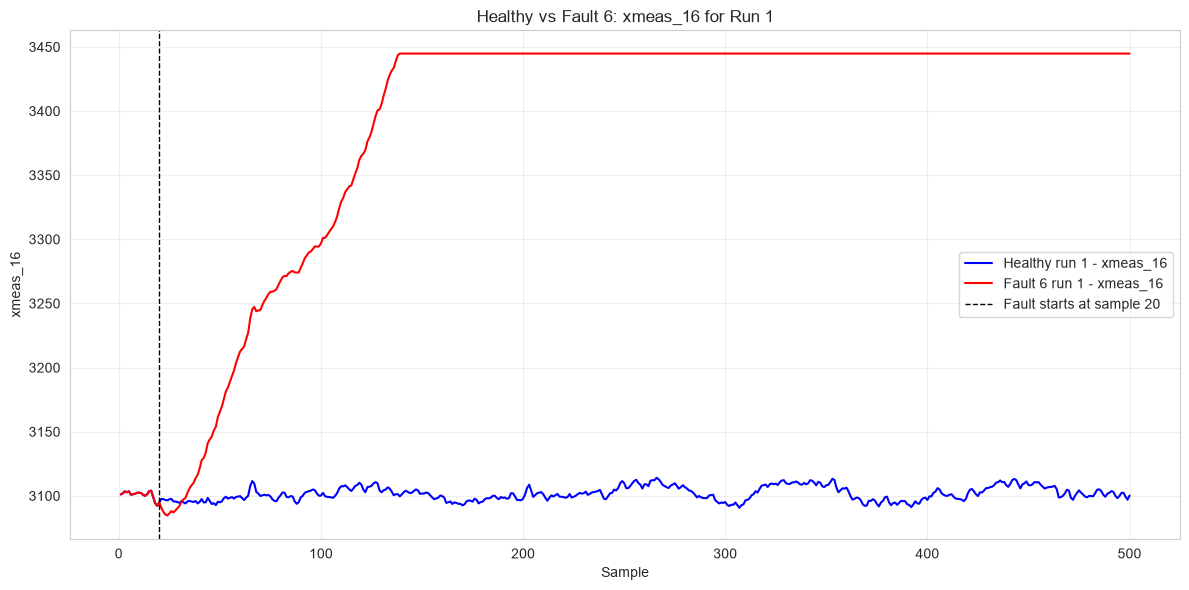

Saved plot to fault6_sensor_comparison.png


In [ ]:
# Cell 7: Visualize the Same Sensor in Healthy vs Faulty Data

# Plot the healthy trace in blue and the faulty trace in red.
plt.figure(figsize=(12, 6))

plt.plot(
    healthy_selected['sample'],
    healthy_selected[sensor],
    label=f'Healthy run {run_id} - {sensor}',
    color='blue',
    linewidth=1.5,
)

plt.plot(
    faulty_selected['sample'],
    faulty_selected[sensor],
    label=f'Fault {fault_number} run {run_id} - {sensor}',
    color='red',
    linewidth=1.5,
)

# Add a vertical line to mark where the fault is introduced.
plt.axvline(
    fault_start,
    color='black',
    linestyle='--',
    linewidth=1,
    label=f'Fault starts at sample {fault_start}',
)

# Labels and title make the chart easier to interpret.
plt.title(f'Healthy vs Fault {fault_number}: {sensor} for Run {run_id}')
plt.xlabel('Sample')
plt.ylabel(sensor)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Save the plot so it can be reviewed later.
plt.savefig('fault6_sensor_comparison.png', dpi=150)
plt.show()

print('Saved plot to fault6_sensor_comparison.png')

## First-pass binary fault detector

This section trains a simple classifier to answer a practical question:
- Is a sample healthy (`0`) or faulty (`1`)?

The labels are built from the simulation setup:
- all rows from the fault-free data are healthy,
- in the faulty data, rows with `sample > 20` are treated as faulty after the fault starts,
- rows with `sample <= 20` are kept as extra healthy examples.

We will use only the 52 sensor/valve columns and evaluate the model on unseen data.

In [ ]:
from pathlib import Path

import pandas as pd
import pyreadr
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.model_selection import train_test_split

# ------------------------------------------------------------
# 1) Load the training datasets
# ------------------------------------------------------------
project_root = Path.cwd()
fault_free_path = project_root / "../data/TEP_FaultFree_Training.RData"
faulty_path = project_root / "../data/TEP_Faulty_Training.RData"

result_fault_free = pyreadr.read_r(fault_free_path)
fault_free = result_fault_free["fault_free_training"]

result_faulty = pyreadr.read_r(faulty_path)
faulty = result_faulty["faulty_training"]

print(f"Loaded fault-free shape: {fault_free.shape}")
print(f"Loaded faulty shape: {faulty.shape}")

# ------------------------------------------------------------
# 2) Create binary labels
#    healthy = 0
#    faulty = 1 when sample > 20
#    early faulty rows (sample <= 20) are used as extra healthy
# ------------------------------------------------------------
# The bookkeeping columns are kept only long enough to filter rows.
bookkeeping_cols = ["faultNumber", "simulationRun", "sample"]

# All fault-free rows are healthy by definition.
healthy_pool = fault_free.assign(label=0)

# In the faulty data, the first 20 samples are considered pre-fault.
# We treat those as extra healthy examples.
healthy_pool = pd.concat(
    [healthy_pool, faulty.loc[faulty["sample"] <= 20].assign(label=0)],
    ignore_index=True,
)

# After sample 20, the fault is assumed to be active.
# These rows become the positive class.
faulty_pool = faulty.loc[faulty["sample"] > 20].assign(label=1)

print(f"Healthy pool size before sampling: {len(healthy_pool)}")
print(f"Faulty pool size before sampling: {len(faulty_pool)}")

# ------------------------------------------------------------
# 3) Keep only the 52 sensor/valve columns as features
#    Drop bookkeeping columns and any non-feature metadata.
# ------------------------------------------------------------
feature_cols = [
    col for col in faulty.columns
    if col.startswith("xmeas_") or col.startswith("xmv_")
]

# We will use the same feature columns for both classes.
X_all = pd.concat(
    [
        healthy_pool[feature_cols],
        faulty_pool[feature_cols],
    ],
    ignore_index=True,
)

y_all = pd.concat(
    [healthy_pool["label"], faulty_pool["label"]],
    ignore_index=True,
)

# ------------------------------------------------------------
# 4) Sample a balanced subset so this first version runs quickly
#    and still gives a realistic estimate.
# ------------------------------------------------------------
# We use a fixed sample size so the notebook output is reproducible.
sample_per_class = 20_000

healthy_sample = healthy_pool.sample(
    n=min(sample_per_class, len(healthy_pool)),
    random_state=42,
    replace=False,
)
faulty_sample = faulty_pool.sample(
    n=min(sample_per_class, len(faulty_pool)),
    random_state=42,
    replace=False,
)

sampled_df = pd.concat(
    [healthy_sample, faulty_sample],
    ignore_index=True,
)

# Rebuild the feature matrix from the sampled subset.
X = sampled_df[feature_cols]
y = sampled_df["label"]

# ------------------------------------------------------------
# 5) Split into train and test sets
# ------------------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

print(f"Train size: {len(X_train)}")
print(f"Test size: {len(X_test)}")
print(f"Train label counts:\n{y_train.value_counts().sort_index()}")
print(f"Test label counts:\n{y_test.value_counts().sort_index()}")

# ------------------------------------------------------------
# 6) Train the random forest classifier
# ------------------------------------------------------------
rf_model = RandomForestClassifier(
    n_estimators=300,
    min_samples_leaf=2,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1,
)
rf_model.fit(X_train, y_train)

# ------------------------------------------------------------
# 7) Evaluate on the held-out test set
# ------------------------------------------------------------
y_pred = rf_model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

# Confusion matrix layout:
#   row 0 = true healthy
#   row 1 = true faulty
#   col 0 = predicted healthy
#   col 1 = predicted faulty
false_alarms = cm[0, 1]  # healthy flagged as faulty
missed_faults = cm[1, 0]  # faulty flagged as healthy

print(f"Accuracy: {accuracy:.4f}")
print("Confusion matrix (rows=true, cols=pred):")
print(pd.DataFrame(
    cm,
    index=["healthy (true)", "faulty (true)"],
    columns=["pred healthy", "pred faulty"],
))
print(f"False alarms (healthy flagged faulty): {false_alarms}")
print(f"Missed faults (faulty flagged healthy): {missed_faults}")


Loaded fault-free shape: (250000, 55)
Loaded faulty shape: (5000000, 55)
Healthy pool size before sampling: 450000
Faulty pool size before sampling: 4800000
Train size: 32000
Test size: 8000
Train label counts:
label
0    16000
1    16000
Name: count, dtype: int64
Test label counts:
label
0    4000
1    4000
Name: count, dtype: int64
Accuracy: 0.8578
Confusion matrix (rows=true, cols=pred):
                pred healthy  pred faulty
healthy (true)          3732          268
faulty (true)            870         3130
False alarms (healthy flagged faulty): 268
Missed faults (faulty flagged healthy): 870


## Per-fault detection analysis

The overall accuracy hides a lot of variation. This section checks how well the detector performs for each individual fault type by computing the fraction of truly faulty samples that the model correctly flags as faulty.

A low value for a fault means that the model is missing many samples from that fault class, while a high value means the fault is easier to recognize from the selected features.

Per-fault detection rates on the test split (best to worst):
 faultNumber  true_faulty_rows  correctly_detected_rows  detection_rate
      4.0000               201                      201          1.0000
      6.0000               193                      193          1.0000
      7.0000               179                      179          1.0000
     12.0000               218                      217          0.9954
     14.0000               208                      207          0.9952
      2.0000               187                      186          0.9947
      1.0000               162                      161          0.9938
      8.0000               219                      213          0.9726
     17.0000               176                      165          0.9375
     18.0000               224                      201          0.8973
     13.0000               200                      171          0.8550
     16.0000               211                      179          0.8483
   

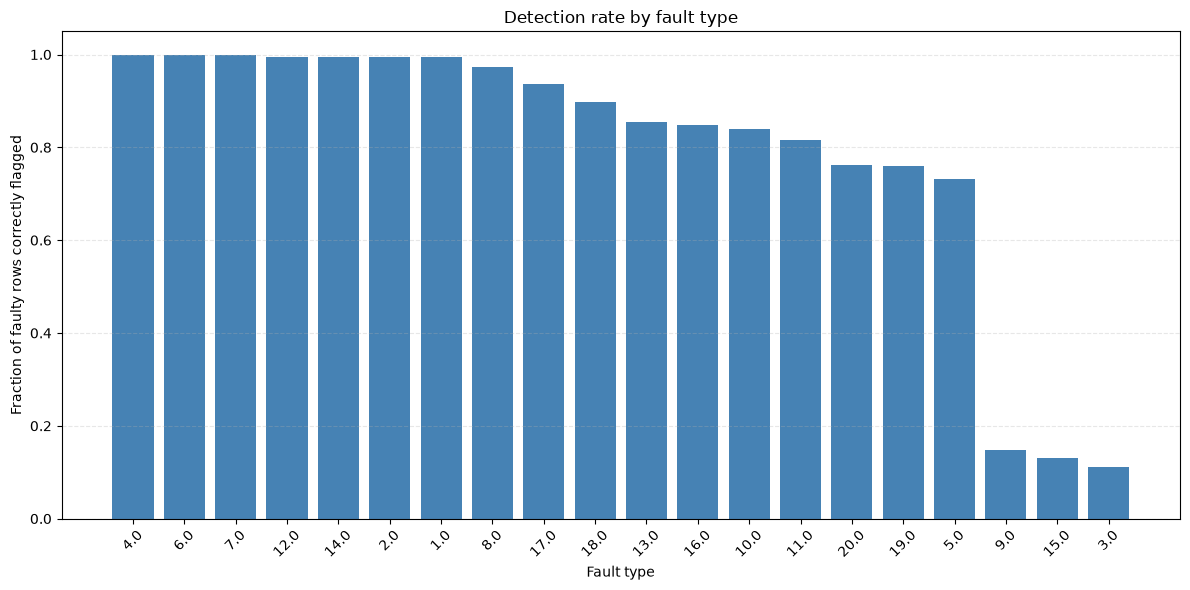


Worst-detected fault types:
 faultNumber  true_faulty_rows  correctly_detected_rows  detection_rate
     19.0000               204                      155          0.7598
      5.0000               164                      120          0.7317
      9.0000               210                       31          0.1476
     15.0000               200                       26          0.1300
      3.0000               224                       25          0.1116


In [ ]:
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Diagnose the detector by fault type
# ------------------------------------------------------------
# We use the held-out test split so the rates are based on
# previously unseen samples.

test_frame = sampled_df.loc[X_test.index].copy()
test_frame["predicted_label"] = rf_model.predict(X_test)
test_frame["correctly_detected"] = (
    (test_frame["predicted_label"] == 1) & (test_frame["label"] == 1)
)

# Compute how many true faulty samples exist for each fault type,
# and how many of those the model correctly flags.
fault_detection = (
    test_frame.loc[test_frame["label"] == 1]
    .groupby("faultNumber")
    .agg(
        true_faulty_rows=("label", "size"),
        correctly_detected_rows=("correctly_detected", "sum"),
    )
    .assign(
        detection_rate=lambda df: df["correctly_detected_rows"] / df["true_faulty_rows"]
    )
    .sort_values("detection_rate", ascending=False)
    .reset_index()
)

print("Per-fault detection rates on the test split (best to worst):")
print(fault_detection.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# Plot the sorted results so the easier and harder faults are easy to spot.
fig, ax = plt.subplots(figsize=(12, 6))
ax.bar(
    fault_detection["faultNumber"].astype(str),
    fault_detection["detection_rate"],
    color="steelblue",
)
ax.set_title("Detection rate by fault type")
ax.set_xlabel("Fault type")
ax.set_ylabel("Fraction of faulty rows correctly flagged")
ax.set_ylim(0, 1.05)
ax.grid(axis="y", linestyle="--", alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# A quick summary of the weakest faults.
worst_faults = fault_detection.tail(5).copy()
print("\nWorst-detected fault types:")
print(worst_faults.to_string(index=False, float_format=lambda x: f"{x:.4f}"))


## Time-aware detector improvement

The previous model looked at each sample independently. This section adds run-specific rolling features so the classifier can use short-term history within each simulation run.

For each sensor/valve column, we compute:
- rolling mean over the last 15 samples,
- rolling standard deviation over the last 15 samples, and
- a simple rate-of-change feature based on the difference over 15 samples.

These are computed separately for each `(faultNumber, simulationRun)` pair so that windows never leak across runs.

/var/folders/qp/gy4yll653kn6d8874bphj18c0000gn/T/ipykernel_40319/4063022008.py:39: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out[f"{col}_roll_std"] = grouped[col].transform(
/var/folders/qp/gy4yll653kn6d8874bphj18c0000gn/T/ipykernel_40319/4063022008.py:45: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out[f"{col}_roll_delta"] = grouped[col].transform(
/var/folders/qp/gy4yll653kn6d8874bphj18c0000gn/T/ipykernel_40319/4063022008.py:36: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `f

Train size (time-aware): 32000
Test size (time-aware): 8000
Accuracy (time-aware): 0.9425
Confusion matrix (rows=true, cols=pred):
                pred healthy  pred faulty
healthy (true)          3741          259
faulty (true)            201         3799
False alarms (time-aware): 259
Missed faults (time-aware): 201

Per-fault detection rates after adding rolling features:
 faultNumber  true_faulty_rows  correctly_detected_rows  detection_rate
           1               183                      183          1.0000
           4               197                      197          1.0000
           6               194                      194          1.0000
           7               183                      183          1.0000
          14               214                      213          0.9953
           8               202                      201          0.9950
          12               232                      229          0.9871
           2               185                

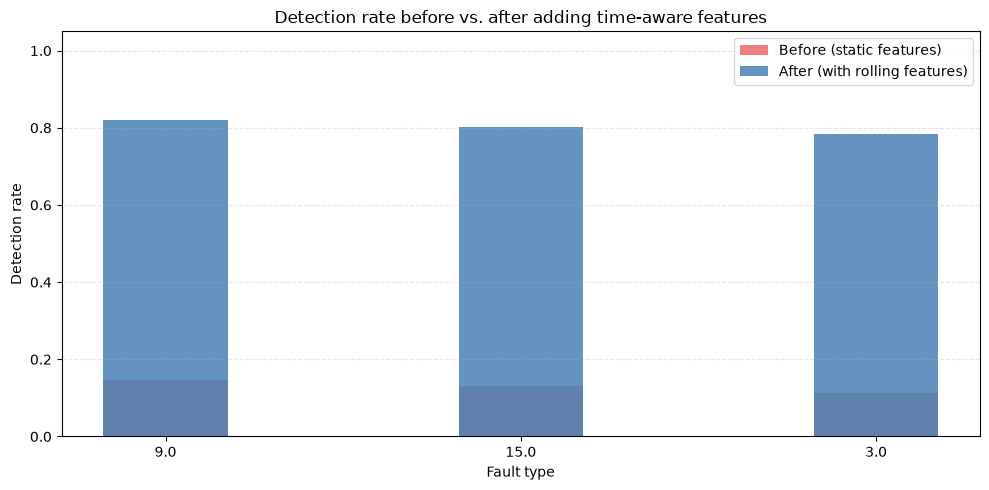

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.model_selection import train_test_split

# ------------------------------------------------------------
# Rebuild the baseline comparison from the earlier per-fault run.
# ------------------------------------------------------------
# Keep the previous per-fault rates so we can compare before vs. after.
baseline_detection = fault_detection.copy()

# ------------------------------------------------------------
# Helper: add run-specific rolling features for time awareness
# ------------------------------------------------------------
WINDOW = 15


def add_run_aware_rolling_features(df: pd.DataFrame, feature_columns: list[str], window: int = WINDOW) -> pd.DataFrame:
    """
    Add rolling mean, rolling std, and rate-of-change features.
    The rolling stats are computed separately within each run so they
    do not mix samples from different simulation runs.
    """
    out = df.copy()
    out = out.sort_values(
        ["faultNumber", "simulationRun", "sample"],
        kind="mergesort",
    ).reset_index(drop=True)

    grouped = out.groupby(["faultNumber", "simulationRun"], sort=False)

    for col in feature_columns:
        # Rolling mean and std over the last `window` samples.
        out[f"{col}_roll_mean"] = grouped[col].transform(
            lambda s: s.rolling(window=window, min_periods=1).mean()
        )
        out[f"{col}_roll_std"] = grouped[col].transform(
            lambda s: s.rolling(window=window, min_periods=1).std(ddof=0).fillna(0)
        )

        # A simple rate-of-change feature: compare the current value to the value
        # seen `window` samples earlier within the same run.
        out[f"{col}_roll_delta"] = grouped[col].transform(
            lambda s: (s - s.shift(window)).fillna(0) / window
        )

    return out

# ------------------------------------------------------------
# 1) Create time-aware features on the sampled dataset.
# ------------------------------------------------------------
# Reuse the same sampled subset so the comparison is fair.
sampled_df_time = add_run_aware_rolling_features(
    sampled_df,
    feature_cols,
    window=WINDOW,
)

# Add the original static features plus the new rolling features.
new_feature_cols = feature_cols + [
    f"{col}_roll_mean" for col in feature_cols
] + [
    f"{col}_roll_std" for col in feature_cols
] + [
    f"{col}_roll_delta" for col in feature_cols
]

# ------------------------------------------------------------
# 2) Split into train and test using the same strategy as before.
# ------------------------------------------------------------
X_train_time, X_test_time, y_train_time, y_test_time = train_test_split(
    sampled_df_time[new_feature_cols],
    sampled_df_time["label"],
    test_size=0.2,
    random_state=42,
    stratify=sampled_df_time["label"],
)

print(f"Train size (time-aware): {len(X_train_time)}")
print(f"Test size (time-aware): {len(X_test_time)}")

# ------------------------------------------------------------
# 3) Retrain the model with the expanded feature set.
# ------------------------------------------------------------
rf_model_time = RandomForestClassifier(
    n_estimators=300,
    min_samples_leaf=2,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1,
)
rf_model_time.fit(X_train_time, y_train_time)

# ------------------------------------------------------------
# 4) Evaluate overall performance.
# ------------------------------------------------------------
y_pred_time = rf_model_time.predict(X_test_time)
accuracy_time = accuracy_score(y_test_time, y_pred_time)
cm_time = confusion_matrix(y_test_time, y_pred_time, labels=[0, 1])

false_alarms_time = cm_time[0, 1]
missed_faults_time = cm_time[1, 0]

print(f"Accuracy (time-aware): {accuracy_time:.4f}")
print("Confusion matrix (rows=true, cols=pred):")
print(pd.DataFrame(
    cm_time,
    index=["healthy (true)", "faulty (true)"],
    columns=["pred healthy", "pred faulty"],
))
print(f"False alarms (time-aware): {false_alarms_time}")
print(f"Missed faults (time-aware): {missed_faults_time}")

# ------------------------------------------------------------
# 5) Recompute per-fault detection rates.
# ------------------------------------------------------------
# Match the test rows back to their metadata so we can inspect fault-specific results.
test_frame_time = sampled_df_time.loc[X_test_time.index].copy()
test_frame_time["predicted_label"] = rf_model_time.predict(X_test_time)

detection_time = (
    test_frame_time.loc[test_frame_time["label"] == 1]
    .groupby("faultNumber")
    .agg(
        true_faulty_rows=("label", "size"),
        correctly_detected_rows=(
            "predicted_label",
            lambda s: int((s == 1).sum())
        ),
    )
    .assign(
        detection_rate=lambda df: df["correctly_detected_rows"] / df["true_faulty_rows"]
    )
    .sort_values("detection_rate", ascending=False)
    .reset_index()
)

detection_time["faultNumber"] = detection_time["faultNumber"].astype(int)

print("\nPer-fault detection rates after adding rolling features:")
print(detection_time.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# ------------------------------------------------------------
# 6) Compare before vs. after for the hardest faults.
# ------------------------------------------------------------
comparison = (
    baseline_detection.merge(
        detection_time,
        on="faultNumber",
        suffixes=("_before", "_after"),
    )
    .sort_values("detection_rate_after", ascending=False)
    .reset_index(drop=True)
)

comparison["delta"] = (
    comparison["detection_rate_after"] - comparison["detection_rate_before"]
)

print("\nBefore vs. after comparison (sorted by after):")
print(comparison.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

hard_faults = [3, 9, 15]
comparison_hard = comparison[comparison["faultNumber"].isin(hard_faults)].copy()
print("\nFocused comparison for hardest faults:")
print(comparison_hard.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# ------------------------------------------------------------
# 7) Visualize the before/after comparison for the hardest faults.
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(
    comparison_hard["faultNumber"].astype(str),
    comparison_hard["detection_rate_before"],
    width=0.35,
    label="Before (static features)",
    color="lightcoral",
)
ax.bar(
    comparison_hard["faultNumber"].astype(str),
    comparison_hard["detection_rate_after"],
    width=0.35,
    label="After (with rolling features)",
    color="steelblue",
    alpha=0.85,
)
ax.set_title("Detection rate before vs. after adding time-aware features")
ax.set_xlabel("Fault type")
ax.set_ylabel("Detection rate")
ax.set_ylim(0, 1.05)
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()


## Leakage-safe evaluation (split by run)

The previous time-aware experiment used a row-level split, which can let rolling windows leak information from the same simulation run into both train and test.

This section fixes that by splitting on the full `(faultNumber, simulationRun)` key so every run stays entirely in either train or test. We then compare:
- the original static model (no rolling features), and
- the time-aware model (with rolling features).

This is the most honest evaluation for the detector because the test set is truly unseen at the run level.

In [ ]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.model_selection import train_test_split

# ------------------------------------------------------------
# Leakage-safe evaluation: split by entire simulation runs.
# ------------------------------------------------------------
# This avoids train/test leakage for the rolling features because
# the model never sees a sample from the same run in both splits.

# We use the same labels and sample sizes as before.
# The previous row-level evaluation numbers are kept for comparison.
previous_accuracy = 0.8578
previous_false_alarms = 268
previous_missed_faults = 870
previous_time_aware_accuracy = 0.9425

# ------------------------------------------------------------
# Helper function to compute metrics and per-fault rates.
# ------------------------------------------------------------
def summarize_metrics(df_eval, X_eval, y_true, y_pred):
    # Align predictions to the evaluation dataframe by index.
    pred_series = pd.Series(y_pred, index=X_eval.index, name="pred")
    eval_df = df_eval.copy()
    eval_df["pred"] = pred_series

    accuracy = accuracy_score(y_true, y_pred)
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    false_alarms = int(cm[0, 1])
    missed_faults = int(cm[1, 0])

    per_fault = (
        eval_df.loc[eval_df["label"] == 1]
        .groupby("faultNumber")
        .agg(
            true_faulty_rows=("label", "size"),
            correctly_detected_rows=("pred", lambda s: int((s == 1).sum())),
        )
        .assign(
            detection_rate=lambda d: d["correctly_detected_rows"] / d["true_faulty_rows"]
        )
        .sort_values("detection_rate", ascending=False)
        .reset_index()
    )

    return accuracy, cm, false_alarms, missed_faults, per_fault

# ------------------------------------------------------------
# 1) Create a leakage-safe split by run.
# ------------------------------------------------------------
run_key = sampled_df[["faultNumber", "simulationRun"]].drop_duplicates().reset_index(drop=True)
train_runs, test_runs = train_test_split(
    run_key,
    test_size=0.2,
    random_state=42,
    stratify=run_key["faultNumber"],
)

train_run_ids = set(
    map(tuple, train_runs[["faultNumber", "simulationRun"]].itertuples(index=False, name=None))
)
test_run_ids = set(
    map(tuple, test_runs[["faultNumber", "simulationRun"]].itertuples(index=False, name=None))
)

train_mask = sampled_df[["faultNumber", "simulationRun"]].apply(tuple, axis=1).isin(train_run_ids)
test_mask = sampled_df[["faultNumber", "simulationRun"]].apply(tuple, axis=1).isin(test_run_ids)

train_df = sampled_df.loc[train_mask].copy()
test_df = sampled_df.loc[test_mask].copy()

print(f"Train rows after run-level split: {len(train_df)}")
print(f"Test rows after run-level split: {len(test_df)}")

# ------------------------------------------------------------
# 2) Static-feature baseline on the same clean split.
# ------------------------------------------------------------
X_train_static = train_df[feature_cols]
X_test_static = test_df[feature_cols]
y_train_static = train_df["label"]
y_test_static = test_df["label"]

rf_static = RandomForestClassifier(
    n_estimators=300,
    min_samples_leaf=2,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1,
)
rf_static.fit(X_train_static, y_train_static)
pred_static = rf_static.predict(X_test_static)

acc_static, cm_static, fa_static, mf_static, per_fault_static = summarize_metrics(
    test_df, X_test_static, y_test_static, pred_static
)

# ------------------------------------------------------------
# 3) Time-aware features computed only within each run.
# ------------------------------------------------------------
WINDOW = 15


def add_run_aware_rolling_features(df, feature_columns, window=WINDOW):
    out = df.copy().sort_values(
        ["faultNumber", "simulationRun", "sample"],
        kind="mergesort",
    ).reset_index(drop=True)
    grouped = out.groupby(["faultNumber", "simulationRun"], sort=False)

    for col in feature_columns:
        out[f"{col}_roll_mean"] = grouped[col].transform(
            lambda s: s.rolling(window=window, min_periods=window).mean()
        )
        out[f"{col}_roll_std"] = grouped[col].transform(
            lambda s: s.rolling(window=window, min_periods=window).std(ddof=0).fillna(0)
        )
        out[f"{col}_roll_delta"] = grouped[col].transform(
            lambda s: (s - s.shift(window)).fillna(0) / window
        )
    return out

train_df_time = add_run_aware_rolling_features(train_df, feature_cols, window=WINDOW)
test_df_time = add_run_aware_rolling_features(test_df, feature_cols, window=WINDOW)

new_feature_cols = (
    feature_cols
    + [f"{c}_roll_mean" for c in feature_cols]
    + [f"{c}_roll_std" for c in feature_cols]
    + [f"{c}_roll_delta" for c in feature_cols]
)

X_train_time = train_df_time[new_feature_cols]
X_test_time = test_df_time[new_feature_cols]
y_train_time = train_df_time["label"]
y_test_time = test_df_time["label"]

rf_time = RandomForestClassifier(
    n_estimators=300,
    min_samples_leaf=2,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1,
)
rf_time.fit(X_train_time, y_train_time)
pred_time = rf_time.predict(X_test_time)

acc_time, cm_time, fa_time, mf_time, per_fault_time = summarize_metrics(
    test_df_time, X_test_time, y_test_time, pred_time
)

# ------------------------------------------------------------
# 4) Print the leakage-safe results.
# ------------------------------------------------------------
print("\nLeakage-safe eval: static features")
print(f"Accuracy: {acc_static:.4f}")
print(f"False alarms: {fa_static}")
print(f"Missed faults: {mf_static}")
print(pd.DataFrame(
    cm_static,
    index=["healthy (true)", "faulty (true)"],
    columns=["pred healthy", "pred faulty"],
))

print("\nLeakage-safe eval: time-aware features")
print(f"Accuracy: {acc_time:.4f}")
print(f"False alarms: {fa_time}")
print(f"Missed faults: {mf_time}")
print(pd.DataFrame(
    cm_time,
    index=["healthy (true)", "faulty (true)"],
    columns=["pred healthy", "pred faulty"],
))

print("\nPer-fault detection rates (time-aware, leakage-safe):")
print(per_fault_time.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

hard_faults = [3, 9, 15]
print("\nHard-fault focus (time-aware, leakage-safe):")
print(
    per_fault_time[per_fault_time["faultNumber"].isin(hard_faults)]
    .to_string(index=False, float_format=lambda x: f"{x:.4f}")
)

print("\nComparison vs. earlier row-level evaluations:")
print(
    f"Previous static row-level accuracy: {previous_accuracy:.4f}"
    f"  -> clean run-level static accuracy: {acc_static:.4f}"
)
print(
    f"Previous row-level false alarms / missed faults: {previous_false_alarms} / {previous_missed_faults}"
    f"  -> clean run-level static false alarms / missed faults: {fa_static} / {mf_static}"
)
print(
    f"Previous time-aware row-level accuracy: {previous_time_aware_accuracy:.4f}"
    f"  -> clean run-level time-aware accuracy: {acc_time:.4f}"
)


Train rows after run-level split: 31862
Test rows after run-level split: 8138


/var/folders/qp/gy4yll653kn6d8874bphj18c0000gn/T/ipykernel_40319/435387159.py:115: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out[f"{col}_roll_std"] = grouped[col].transform(
/var/folders/qp/gy4yll653kn6d8874bphj18c0000gn/T/ipykernel_40319/435387159.py:118: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out[f"{col}_roll_delta"] = grouped[col].transform(
/var/folders/qp/gy4yll653kn6d8874bphj18c0000gn/T/ipykernel_40319/435387159.py:112: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `f


Leakage-safe eval: static features
Accuracy: 0.8490
False alarms: 358
Missed faults: 871
                pred healthy  pred faulty
healthy (true)          3648          358
faulty (true)            871         3261

Leakage-safe eval: time-aware features
Accuracy: 0.8548
False alarms: 690
Missed faults: 492
                pred healthy  pred faulty
healthy (true)          3316          690
faulty (true)            492         3640

Per-fault detection rates (time-aware, leakage-safe):
 faultNumber  true_faulty_rows  correctly_detected_rows  detection_rate
      1.0000               207                      207          1.0000
      4.0000               193                      193          1.0000
      7.0000               188                      188          1.0000
      2.0000               212                      212          1.0000
     14.0000               228                      227          0.9956
      6.0000               205                      204          0.9951
     